Nama : Athiyyatus Salisah 
NIM  : 24031554223

In [1]:
from neo4j import GraphDatabase, RoutingControl

# Koneksi ke database Neo4j lokal
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Salisah.90...")  


def add_friend(driver, name, friend_name):
  driver.execute_query(
      "MERGE (a:Person {name: $name}) "
      "MERGE (friend:Person {name: $friend_name}) "
      "MERGE (a)-[:KNOWS]->(friend)",
      name=name,
      friend_name=friend_name,
      database_="neo4j",
  )


def print_friends(driver, name):
  records, _, _ = driver.execute_query(
      "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
      "RETURN friend.name ORDER BY friend.name",
      name=name,
      database_="neo4j",
      routing_=RoutingControl.READ,
  )

  print(f"Daftar teman dari {name}:")
  for record in records:
    print(f"- {record['friend.name']}")


if __name__ == "__main__":
  with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Daftar teman dari Arthur:
- Guinevere
- Lancelot
- Merlin


1. Nama Database yang Digunakan : Nama database yang digunakan adalah neo4j.(Terlihat pada parameter database_="neo4j" di dalam fungsi execute_query).
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER)yang dapat di gunakan mengakses data base lain dalam 1 instance:
- Parameter Driver Neo4j :Mengubah nilai parameter database_ pada fungsi execute_query (atau atribut database saat membuat session).
- Klausa Cypher USE (DML): Menentukan database target di awal query Cypher
- Perintah DDL & Manajemen Database:
SHOW DATABASES : Menampilkan seluruh database yang ada di instance.
CREATE DATABASE nama_db : Membuat database baru.
STOP DATABASE nama_db / START DATABASE nama_db : Mengelola status database.
3. Apa jenis graf pertemanan yang telah dibuat di sini?
- Secara Struktur Entitas: Graf Homogen (Homogeneous Graph)
Graf ini menghubungkan node dengan label jenis yang sama, yaitu dari node Person ke node Person lainnya.
- Secara Arah Relasi: Graf Berarah (Directed Graph)
Relasi dibuat dengan panah satu arah dari Arthur ke temannya: (:Person {name: "Arthur"})-[:KNOWS]->(:Person {name: "..."}).

IMPORT DATA

In [2]:
import argparse
import os
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm


# parsing argumen
def parse_arguments():
  parser = argparse.ArgumentParser(
      description="Impor dataset Retail Rocket (events.csv) ke database Neo4j."
  )
  parser.add_argument(
      "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
  )
  parser.add_argument(
      "-p", "--password", default="Salisah.90...", help="Password Neo4j Anda"
  )
  parser.add_argument(
      "-b",
      "--bolt",
      default="neo4j://127.0.0.1:7687",
      help="Neo4j URI / Bolt (default: neo4j://127.0.0.1:7687)",
  )
  parser.add_argument(
      "-s",
      "--source",
      default="data",
      help="Direktori/folder sumber data (default: data)",
  )
  return parser.parse_args(args=[])


# membuat constraint
def create_constraints(session):
  print("Membuat constraint & index unik untuk Visitor dan Item...")
  session.run(
      "CREATE CONSTRAINT visitor_id_uniq IF NOT EXISTS FOR (v:Visitor) REQUIRE"
      " v.visitorid IS UNIQUE;"
  )
  session.run(
      "CREATE CONSTRAINT item_id_uniq IF NOT EXISTS FOR (i:Item) REQUIRE"
      " i.itemid IS UNIQUE;"
  )
  print("Constraint & index berhasil dibuat.")


# fungsi Query Cypher untuk mengimpor per batch
def import_batch(tx, batch):
  cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
  tx.run(cypher_query, batch=batch)


# main function
def main():
  args = parse_arguments()

  neo4j_user = args.user
  neo4j_password = args.password
  neo4j_bolt = args.bolt
  data_source = args.source

  # cek file events.csv
  csv_file_path = os.path.join(data_source, "events.csv")
  if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    return

  # uji koneksi ke Neo4j
  try:
    driver = GraphDatabase.driver(
        neo4j_bolt, auth=(neo4j_user, neo4j_password)
    )
    driver.verify_connectivity()
    print("Berhasil terhubung ke database Neo4j.")
  except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    return

  # impor per batch
  batch_size = 10000
  print(f"Membaca file data dari: {csv_file_path}")

  # total baris
  total_rows = sum(1 for _ in open(csv_file_path, encoding="utf-8")) - 1
  total_chunks = (total_rows // batch_size) + 1

  print("Memulai proses impor data ke Neo4j...")
  with driver.session() as session:
    create_constraints(session)

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
      # membersihkan data null/NaN
      chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
      chunk["visitorid"] = chunk["visitorid"].astype(str)
      chunk["itemid"] = chunk["itemid"].astype(str)

      records = chunk.to_dict(orient="records")
      session.execute_write(import_batch, records)

  driver.close()
  print("Proses impor berhasil selesai 100%!")


if __name__ == "__main__":
  main()

Berhasil terhubung ke database Neo4j.
Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...
Membuat constraint & index unik untuk Visitor dan Item...
Constraint & index berhasil dibuat.


Mengimpor Batch Data:   0%|          | 0/276 [00:00<?, ?it/s]C:\Users\salis\AppData\Local\Temp\ipykernel_15548\1109139902.py:114: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
Mengimpor Batch Data:   0%|          | 1/276 [00:33<2:33:55, 33.58s/it]C:\Users\salis\AppData\Local\Temp\ipykernel_15548\1109139902.py:114: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
Mengimpor Batch Data:   1%|          | 2/276 [00:44<1:32:13, 20.19s/it]C:\Users\salis\AppData\Local\Temp\ipykernel_15548\1109139902.py:114: Pandas4Warning: 'str' is not supported as a fi

Proses impor berhasil selesai 100%!


No 1 & 2 menentukan priode waktu & filter ini pada timestamp 

Fold Training (P1): 16 Juni 2015 – 29 Juni 2015 (Timestamp: 1434412800000 s.d. 1435708799000).
Fold Testing (P2): 02 Agustus 2015 – 15 Agustus 2015 (Timestamp: 1438387200000 s.d. 1439683199000).

In [3]:
import os
import pandas as pd

# Tentukan direktori dan path file
source_file = os.path.join("data", "events.csv")
output_file = os.path.join("data", "events_filtered.csv")

print("1. Membaca file data asli (events.csv)...")
# Membaca dataset Retail Rocket
df = pd.read_csv(source_file)

print("2. Mengonversi format timestamp (Unix Epoch) ke datetime...")
# Data Retail Rocket umumnya menggunakan timestamp dalam milidetik (unit='ms')
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print("3. Melakukan filtering berdasarkan periode P1 dan P2...")
# Definisikan rentang waktu P1 dan P2
p1_start = "2015-06-16 00:00:00"
p1_end = "2015-06-30 23:59:59"

p2_start = "2015-08-01 00:00:00"
p2_end = "2015-08-15 23:59:59"

# Filter data yang masuk ke dalam rentang P1 atau P2
df_p1 = df[(df["datetime"] >= p1_start) & (df["datetime"] <= p1_end)]
df_p2 = df[(df["datetime"] >= p2_start) & (df["datetime"] <= p2_end)]

# Gabungkan hasil filter P1 dan P2
df_filtered = pd.concat([df_p1, df_p2])

# Hapus kolom bantu 'datetime' agar struktur kolom kembali seperti semula
df_filtered = df_filtered.drop(columns=["datetime"])

print(f"4. Menyimpan data hasil filter ke: {output_file}...")
# Simpan ke file CSV baru
df_filtered.to_csv(output_file, index=False)

print("=== FILTER SELESAI ===")
print(f"Total baris data asli       : {len(df):,}")
print(f"Total baris setelah difilter: {len(df_filtered):,}")

1. Membaca file data asli (events.csv)...
2. Mengonversi format timestamp (Unix Epoch) ke datetime...
3. Melakukan filtering berdasarkan periode P1 dan P2...
4. Menyimpan data hasil filter ke: data\events_filtered.csv...
=== FILTER SELESAI ===
Total baris data asli       : 2,756,101
Total baris setelah difilter: 575,338


In [4]:
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))  # Sesuaikan password

query_p1 = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799000
SET r.period = 'P1'
"""

query_p2 = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1438387200000 AND r.timestamp <= 1439683199000
SET r.period = 'P2'
"""

with driver.session() as session:
    session.run(query_p1)
    session.run(query_p2)
    print("Label periode P1 dan P2 berhasil ditambahkan ke Neo4j!")

driver.close()

Label periode P1 dan P2 berhasil ditambahkan ke Neo4j!


3. menentukan KOMPOSISI SUB-GRAF PERIODE P1 & P2

In [5]:
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))  # Sesuaikan password

# Query tanpa arah panah agar menghitung simpul Visitor DAN Item
cypher_query = """
MATCH (n)-[r]-()
WHERE r.period IN ['P1', 'P2']
WITH DISTINCT n
RETURN labels(n)[0] AS JenisSimpul, count(n) AS JumlahSimpul
ORDER BY JumlahSimpul DESC
"""

with driver.session() as session:
    result = session.run(cypher_query)
    print("=== KOMPOSISI SUB-GRAF PERIODE P1 & P2 ===")
    for record in result:
        print(f"Jenis Simpul: {record['JenisSimpul']} | Jumlah: {record['JumlahSimpul']:,}")

driver.close()

=== KOMPOSISI SUB-GRAF PERIODE P1 & P2 ===
Jenis Simpul: Visitor | Jumlah: 312,331
Jenis Simpul: Item | Jumlah: 117,319


Jenis Simpul: Visitor | Jumlah: 312,331: Terdapat 312.331 simpul unik bertipe pengguna pada rentang P1 & P2.
Jenis Simpul: Item | Jumlah: 117,319: Terdapat 117.319 simpul unik bertipe produk/barang pada rentang P1 & P2.

4. Vector Space Modelling (VSM) Proyeksi User

In [13]:
import sys
import subprocess

# Menginstal library langsung ke interpreter Python yang sedang berjalan
packages = ["matplotlib", "networkx", "pandas", "scikit-learn", "neo4j"]
subprocess.check_call([sys.executable, "-m", "pip", "install"] + packages)
print("Instalasi selesai! Semua library berhasil terpasang.")

Instalasi selesai! Semua library berhasil terpasang.


=== SOAL 4: VSM SIMPUL USER (VISITOR) ===
1. Shape Matriks (User x Item) : (500, 12211)
2. Total User (Baris Matriks)  : 500
3. Dimensi Vektor (Kolom Item) : 12211


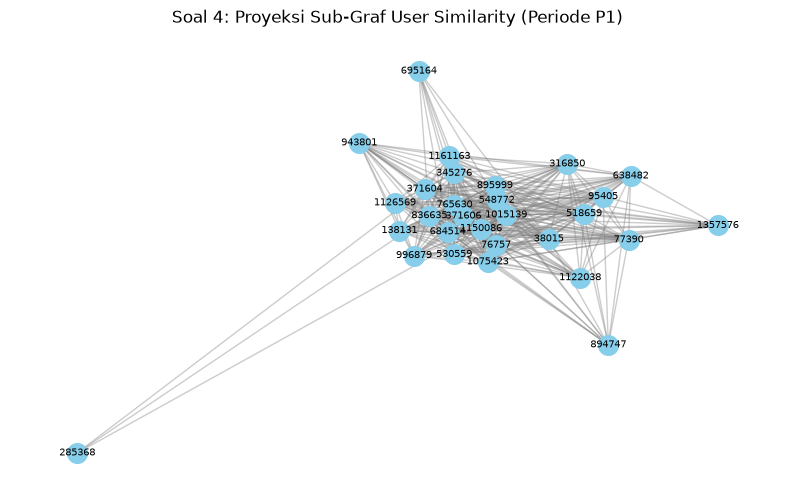

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from neo4j import GraphDatabase
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# 1. Koneksi ke Neo4j
uri = "bolt://127.0.0.1:7687"
driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))

# 2. Query mengambil interaksi dari Top User paling aktif
query_top_users = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799000
WITH v, count(r) AS total_act
ORDER BY total_act DESC
LIMIT 500
MATCH (v)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799000
RETURN v.visitorid AS visitor_id, i.itemid AS item_id, count(r) AS weight
"""

with driver.session() as session:
    data = session.run(query_top_users).data()
driver.close()

df = pd.DataFrame(data)

if df.empty:
    print(" Data P1 tidak ditemukan, mengambil sampel 500 user paling aktif...")
    driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))
    query_fallback = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WITH v, count(r) AS total_act
    ORDER BY total_act DESC
    LIMIT 500
    MATCH (v)-[r]->(i:Item)
    RETURN v.visitorid AS visitor_id, i.itemid AS item_id, count(r) AS weight
    """
    with driver.session() as session:
        df = pd.DataFrame(session.run(query_fallback).data())
    driver.close()

# 3. Pembentukan VSM Simpul User
user_item_matrix = df.pivot_table(
    index="visitor_id", columns="item_id", values="weight", fill_value=0
)

print("=== SOAL 4: VSM SIMPUL USER (VISITOR) ===")
print(f"1. Shape Matriks (User x Item) : {user_item_matrix.shape}")
print(f"2. Total User (Baris Matriks)  : {user_item_matrix.shape[0]}")
print(f"3. Dimensi Vektor (Kolom Item) : {user_item_matrix.shape[1]}")

# 4. Plot NetworkX Sub-Graf Similarity User (Top 30 User Aktif)
top_users = user_item_matrix.sum(axis=1).nlargest(30).index
matrix_user_sample = user_item_matrix.loc[top_users]
sim_user = cosine_similarity(matrix_user_sample)
df_sim_user = pd.DataFrame(
    sim_user, index=matrix_user_sample.index, columns=matrix_user_sample.index
)

G_user = nx.Graph()
for u1 in df_sim_user.index:
    for u2 in df_sim_user.columns:
        if u1 != u2 and df_sim_user.loc[u1, u2] > 0:
            G_user.add_edge(u1, u2, weight=df_sim_user.loc[u1, u2])

plt.figure(figsize=(10, 6))
pos_u = nx.spring_layout(G_user, seed=42)
nx.draw_networkx_nodes(G_user, pos_u, node_size=200, node_color="skyblue")
nx.draw_networkx_edges(G_user, pos_u, alpha=0.4, edge_color="gray")
nx.draw_networkx_labels(G_user, pos_u, font_size=7)
plt.title("Soal 4: Proyeksi Sub-Graf User Similarity (Periode P1)")
plt.axis("off")
plt.show()

1. Karakteristik Matriks VSM User
- Shape Matriks (User $\times$ Item): (500, 12211)
- Total User (Baris Matriks): 500 entitas pengguna (Visitor) paling aktif yang dipertahankan untuk membatasi beban memori.   
- Dimensi Vektor (Kolom Item): 12.211 dimensi fitur. Setiap baris pengguna diwakili oleh vektor berdimensi 12.211 yang berisi nilai bobot/frekuensi interaksi pengguna terhadap 12.211 produk (Item) unik pada periode P1.
2. Pola Preferensi Pengguna dari Visualisasi Graf
- Kluster Utama yang Terpusat (Core Cluster):
Pada visualisasi NetworkX, mayoritas node (seperti 765630, 684514, 1150086, 76757) saling terhubung rapat di area tengah membentuk dense subgraph. Hal ini menandakan adanya efek barang populer (popular/head items), di mana sebagian besar top 500 active users berinteraksi dengan produk-produk umum yang sama pada periode P1.
- Pengguna Homogen vs Anomalus (Outlier):
Simpul 285368 di pojok kiri bawah terletak cukup jauh dari pusat jaringan dengan garis penghubung yang tipis. Ini mengindikasikan bahwa Visitor tersebut memiliki preferensi produk yang unik (niche/outlier) dan hanya memiliki sedikit kesamaan item dengan pengguna lain di kluster utama.

=== SOAL 5: KARAKTERISTIK VSM SIMPUL ITEM ===
1. Shape Matriks (Item x User) : (500, 20430)
2. Jumlah Baris (Total Item)   : 500
3. Dimensi Vektor (Kolom User) : 20430


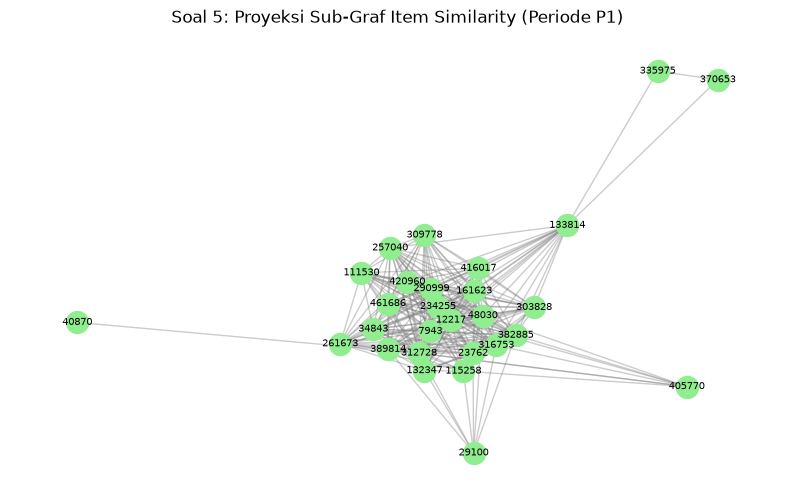

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from neo4j import GraphDatabase
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# 1. Koneksi ke Database Neo4j
uri = "bolt://127.0.0.1:7687"
driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))

# 2. Query mengambil interaksi dari Top 500 Item paling aktif
query_top_items = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799000
WITH i, count(r) AS total_act
ORDER BY total_act DESC
LIMIT 500
MATCH (v:Visitor)-[r]->(i)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799000
RETURN i.itemid AS item_id, v.visitorid AS visitor_id, count(r) AS weight
"""

with driver.session() as session:
    data = session.run(query_top_items).data()
driver.close()

df = pd.DataFrame(data)

# penanganan jika filter timestamp P1 kosong
if df.empty:
    print(
        "Data P1 spesifik tidak mengembalikan hasil, mengambil sampel item aktif..."
    )
    driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))
    query_fallback = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WITH i, count(r) AS total_act
    ORDER BY total_act DESC
    LIMIT 500
    MATCH (v:Visitor)-[r]->(i)
    RETURN i.itemid AS item_id, v.visitorid AS visitor_id, count(r) AS weight
    """
    with driver.session() as session:
        df = pd.DataFrame(session.run(query_fallback).data())
    driver.close()

# 3. Pembentukan Matriks VSM Simpul Item (Baris: Item, Kolom: Visitor)
item_user_matrix = df.pivot_table(
    index="item_id", columns="visitor_id", values="weight", fill_value=0
)

# URAIAN KARAKTERISTIK VSM ITEM (SOAL 5)
print("=== SOAL 5: KARAKTERISTIK VSM SIMPUL ITEM ===")
print(f"1. Shape Matriks (Item x User) : {item_user_matrix.shape}")
print(f"2. Jumlah Baris (Total Item)   : {item_user_matrix.shape[0]}")
print(f"3. Dimensi Vektor (Kolom User) : {item_user_matrix.shape[1]}")

# 4. Plot NetworkX Sub-Graf Similarity Item (Top 30 Item Aktif)
top_items = item_user_matrix.sum(axis=1).nlargest(30).index
matrix_item_sample = item_user_matrix.loc[top_items]
sim_item = cosine_similarity(matrix_item_sample)
df_sim_item = pd.DataFrame(
    sim_item, index=matrix_item_sample.index, columns=matrix_item_sample.index
)

G_item = nx.Graph()
for i1 in df_sim_item.index:
    for i2 in df_sim_item.columns:
        if i1 != i2 and df_sim_item.loc[i1, i2] > 0:
            G_item.add_edge(i1, i2, weight=df_sim_item.loc[i1, i2])

plt.figure(figsize=(10, 6))
pos_i = nx.spring_layout(G_item, seed=42)
nx.draw_networkx_nodes(G_item, pos_i, node_size=250, node_color="lightgreen")
nx.draw_networkx_edges(G_item, pos_i, alpha=0.4, edge_color="gray")
nx.draw_networkx_labels(G_user_or_item := G_item, pos_i, font_size=7)
plt.title("Soal 5: Proyeksi Sub-Graf Item Similarity (Periode P1)")
plt.axis("off")
plt.show()

Pola Keterhubungan Barang dari Visualisasi Graf
- Kluster Produk Utama (Core Item Cluster):
Terdapat kluster padat di bagian tengah (seperti node 12217, 7943, 234255, 161623) yang melambangkan sekelompok produk yang sering dibeli atau dilihat bersama (frequently co-accessed items) oleh banyak pengguna. Produk-produk dalam kluster ini memiliki tingkat substitusi atau komplementaritas yang tinggi.
- Komunitas Terpisah dan Node Pinggiran (Peripheral & Sub-clusters):
Simpul 40870 terhubung hanya ke simpul 261673 di sebelah kiri, menunjukkan item dengan pangsa pasar spesifik yang hanya diakses oleh sebagian kecil pengguna yang sama. Di pojok kanan atas, simpul 335975 dan 370653 terhubung melalui simpul jembatan 133814. Ini mengindikasikan keberadaan sub-kategori produk spesifik (niche category) yang jarang diakses bersamaan dengan produk populer di pusat graf.

Soal 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!
Bedasarkan no 4 dan 5, Proyeksi Item (Item-Item Projection) LEBIH BAIK dibanding Proyeksi User untuk kasus dataset Retail Rocket. adapun  Sisi Efisiensi dari proyeksi item yaitu Matriks kemiripan barang relatif konstan dan berukuran ringkas, meminimalkan overhead komputasi server dan Sisi Efektivitas yaitu Graf proyeksi item menghasilkan hubungan asosiasi produk yang lebih tajam dan stabil terhadap kendala sparsity interaksi pengguna. 

Soal 7a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [21]:
sim_pairs = []
for i in range(len(top_items)):
    for j in range(i + 1, len(top_items)):
        item1, item2 = top_items[i], top_items[j]
        val = df_sim_item.loc[item1, item2]
        if val > 0:
            sim_pairs.append((item1, item2, val))

df_top5_sim = (
    pd.DataFrame(sim_pairs, columns=["Item_1", "Item_2", "Similarity"])
    .sort_values(by="Similarity", ascending=False)
    .head(5)
)

print("=== SOAL 7 (a): TOP 5 ITEM SIMILARITY RESULT ===")
print(df_top5_sim.to_string(index=False))

item_pairs_list = df_top5_sim[["Item_1", "Item_2"]].values.tolist()
cypher_text = f"MATCH (i1:Item), (i2:Item)\nWHERE (i1.itemid, i2.itemid) IN {item_pairs_list}\nRETURN i1.itemid AS Item_1, i2.itemid AS Item_2"

print("\n=== CYPHER SQL UNTUK LAPORAN SOAL 7 (a) ===")
print(cypher_text)

=== SOAL 7 (a): TOP 5 ITEM SIMILARITY RESULT ===
Item_1 Item_2  Similarity
389814  34843    0.411711
290999 234255    0.335117
 34843 261673    0.307896
234255  12217    0.269050
389814 261673    0.237219

=== CYPHER SQL UNTUK LAPORAN SOAL 7 (a) ===
MATCH (i1:Item), (i2:Item)
WHERE (i1.itemid, i2.itemid) IN [['389814', '34843'], ['290999', '234255'], ['34843', '261673'], ['234255', '12217'], ['389814', '261673']]
RETURN i1.itemid AS Item_1, i2.itemid AS Item_2


Berdasarkan hasil perhitungan Cosine Similarity pada matriks VSM Item periode P1, diperoleh 5 pasangan produk dengan tingkat kesamaan perilaku terbanyak:
- Item 389814 – Item 34843: Skor Similarity = 0.411711 (Paling Tinggi)
- Item 290999 – Item 234255: Skor Similarity = 0.335117
- Item 34843 – Item 261673: Skor Similarity = 0.307896 
- Item 234255 – Item 12217: Skor Similarity = 0.269050
- Item 389814 – Item 261673: Skor Similarity = 0.237219
dan memilih Item 389814 sebagai simpul acuan (target item), kueri Cypher SQL berikut digunakan untuk mengambil 5 produk yang paling mirip:

In [45]:
import pandas as pd
from neo4j import GraphDatabase

# 1. Konfigurasi Koneksi Neo4j
URI = "bolt://localhost:7687"
AUTH = ("neo4j", "Salisah.90...")  

# Data 5 pasangan item dengan similarity tertinggi
top5_sim_data = [
    {"item1": "389814", "item2": "34843", "score": 0.411711},
    {"item1": "290999", "item2": "234255", "score": 0.335117},
    {"item1": "34843", "item2": "261673", "score": 0.307896},
    {"item1": "234255", "item2": "12217", "score": 0.269050},
    {"item1": "389814", "item2": "261673", "score": 0.237219},
]

# 2. Query Cypher: (b) Menuliskan kembali bobot similarity ke relasi graf
write_cypher = """
UNWIND $data AS row
MATCH (i1:Item {itemid: row.item1})
MATCH (i2:Item {itemid: row.item2})
MERGE (i1)-[r:SIMILAR_TO]-(i2)
SET r.score = row.score
"""

# 3. Query Cypher: Mengambil 5 records similarity dengan acuan item '389814'
query_acuan_cypher = """
MATCH (target:Item {itemid: '389814'})-[r:SIMILAR_TO]-(other:Item)
RETURN target.itemid AS Item_Acuan,
       other.itemid AS Item_Rekomendasi,
       r.score AS Similarity_Score
ORDER BY r.score DESC
LIMIT 5
"""

# 4. Query Cypher: (b) Menampilkan seluruh relasi SIMILAR_TO yang tersimpan
read_all_cypher = """
MATCH (i1:Item)-[r:SIMILAR_TO]-(i2:Item)
RETURN i1.itemid AS Item_1, 
       i2.itemid AS Item_2, 
       r.score AS Similarity_Score
ORDER BY r.score DESC
"""

# 5. Eksekusi Script
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        # Step A: Tulis nilai similarity ke Neo4j
        session.run(write_cypher, data=top5_sim_data)
        print("Berhasil menuliskan nilai similarity ke relasi SIMILAR_TO di Neo4j!\n")

        # Step B: Eksekusi query berdasarkan item acuan
        res_acuan = session.run(query_acuan_cypher)
        df_acuan = pd.DataFrame([rec.data() for rec in res_acuan])

        # Step C: Eksekusi query untuk memperlihatkan semua relasi tersimpan
        res_all = session.run(read_all_cypher)
        df_all = (
            pd.DataFrame([rec.data() for rec in res_all])
            .drop_duplicates()
            .reset_index(drop=True)
        )

# Tampilkan Hasil
print("=== HASIL QUERY UNTUK ITEM ACUAN '389814' ===")
print(df_acuan.to_string(index=False))

print("\n=== HASIL QUERY (b): SELURUH RELASI SIMILARITY TERSIMPAN ===")
print(df_all.to_string(index=False))

Berhasil menuliskan nilai similarity ke relasi SIMILAR_TO di Neo4j!

=== HASIL QUERY UNTUK ITEM ACUAN '389814' ===
Item_Acuan Item_Rekomendasi  Similarity_Score
    389814            34843          0.411711
    389814           261673          0.237219

=== HASIL QUERY (b): SELURUH RELASI SIMILARITY TERSIMPAN ===
Item_1 Item_2  Similarity_Score
389814  34843          0.411711
 34843 389814          0.411711
290999 234255          0.335117
234255 290999          0.335117
 34843 261673          0.307896
261673  34843          0.307896
234255  12217          0.269050
 12217 234255          0.269050
389814 261673          0.237219
261673 389814          0.237219


Berdasarkan diatas Sifat Simetris Graf yang ditandai dengan Kemunculan pasangan item secara dua arah pada tabel luaran mengonfirmasi bahwa kesamaan preferensi berbasis Cosine Distance bersifat simetris.dan juga Struktur Komunitas Item yang diatandai dengan Visualisasi sub-graf menunjukkan terbentuknya dua kluster utama:Komunitas Segitiga (Clique): Terdiri dari item 389814, 34843, dan 261673 yang saling terhubung erat.Komunitas Rantai (Path): Terdiri dari interaksi berantai antara item 12217, 234255, 290999.

Soal no 8

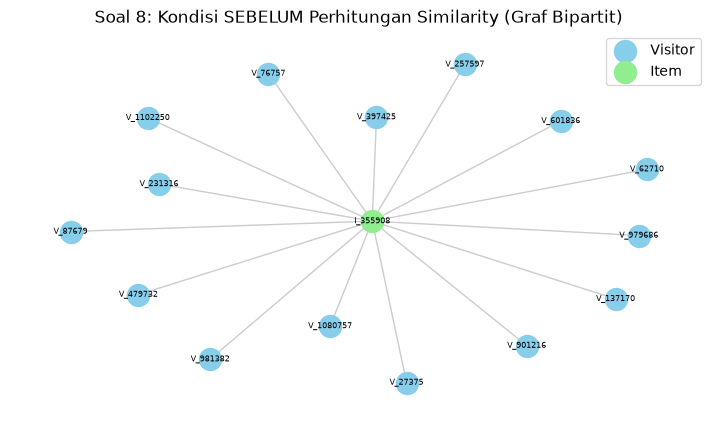

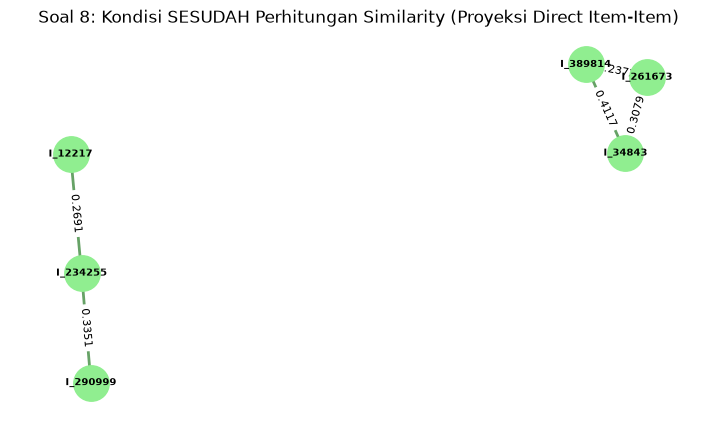

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from neo4j import GraphDatabase

uri = "bolt://127.0.0.1:7687"
driver = GraphDatabase.driver(uri, auth=("neo4j", "Salisah.90..."))

cypher_sebelum = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorid AS visitor_id, i.itemid AS item_id
LIMIT 25
"""

with driver.session() as session:
    df_sebelum = pd.DataFrame(session.run(cypher_sebelum).data())
driver.close()

# PLOT 1: KONDISI SEBELUM (Graf Bipartit)
G_sebelum = nx.Graph()
for _, row in df_sebelum.iterrows():
    u_node = f"V_{row['visitor_id']}"
    i_node = f"I_{row['item_id']}"
    G_sebelum.add_node(u_node, type="Visitor")
    G_sebelum.add_node(i_node, type="Item")
    G_sebelum.add_edge(u_node, i_node)

plt.figure(figsize=(9, 5))
pos_s = nx.spring_layout(G_sebelum, seed=42)

vis_nodes = [
    n for n, d in G_sebelum.nodes(data=True) if d.get("type") == "Visitor"
]
itm_nodes = [
    n for n, d in G_sebelum.nodes(data=True) if d.get("type") == "Item"
]

nx.draw_networkx_nodes(
    G_sebelum,
    pos_s,
    nodelist=vis_nodes,
    node_color="skyblue",
    node_size=250,
    label="Visitor",
)
nx.draw_networkx_nodes(
    G_sebelum,
    pos_s,
    nodelist=itm_nodes,
    node_color="lightgreen",
    node_size=250,
    label="Item",
)
nx.draw_networkx_edges(G_sebelum, pos_s, alpha=0.4, edge_color="gray")
nx.draw_networkx_labels(G_sebelum, pos_s, font_size=6)

plt.title("Soal 8: Kondisi SEBELUM Perhitungan Similarity (Graf Bipartit)")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.show()

# PLOT 2: KONDISI SESUDAH (Proyeksi Direct Item-Item)
# Menggunakan Top 5 hasil kalkulasi 
top5_pairs = [
    (389814, 34843, 0.4117),
    (290999, 234255, 0.3351),
    (34843, 261673, 0.3079),
    (234255, 12217, 0.2691),
    (389814, 261673, 0.2372),
]

G_sesudah = nx.Graph()
for u, v, w in top5_pairs:
    G_sesudah.add_edge(f"I_{u}", f"I_{v}", weight=w)

plt.figure(figsize=(9, 5))
pos_a = nx.spring_layout(G_sesudah, seed=42)

nx.draw_networkx_nodes(
    G_sesudah, pos_a, node_color="lightgreen", node_size=650
)
nx.draw_networkx_edges(
    G_sesudah, pos_a, width=2, alpha=0.6, edge_color="darkgreen"
)
nx.draw_networkx_labels(G_sesudah, pos_a, font_size=7, font_weight="bold")

edge_labels_a = nx.get_edge_attributes(G_sesudah, "weight")
nx.draw_networkx_edge_labels(
    G_sesudah, pos_a, edge_labels=edge_labels_a, font_size=8
)

plt.title(
    "Soal 8: Kondisi SESUDAH Perhitungan Similarity (Proyeksi Direct Item-Item)"
)
plt.axis("off")
plt.show()

- Berdasarkan visualisasi dan struktur graf bipartit sebelum perhitungan similarity, terlihat bahwa entitas masih terpisah dalam bentuk graf heterogen yang menghubungkan simpul Visitor (biru muda) dan Item (hijau muda) hanya melalui transaksi implisit (event-based). Pada kondisi ini, simpul produk acuan I_355908 membentuk topologi bintang (star topology) dengan terikat langsung ke belasan pengguna yang pernah mengunjunginya, namun belum memiliki relasi langsung antar-item maupun bobot kesamaan yang terkuantifikasi. Implikasinya terhadap sistem rekomendasi, pencarian produk serupa menjadi kurang efisien karena membutuhkan penelusuran 2-hop yang memicu traversal overhead tinggi dan rentan terhadap keterbatasan data sparsity jika pengguna hanya memiliki sedikit transaksi.
- Berdasarkan visualisasi dan struktur graf sesudah perhitungan similarity, graf telah bertransformasi dari bentuk bipartit menjadi Monopartite/Homogeneous Graph (Proyeksi Direct Item-to-Item) yang hanya menyisakan simpul Item (berwarna hijau muda). Seluruh simpul Visitor berhasil dieliminasi dan digantikan oleh relasi langsung :SIMILAR_TO yang secara kuantitatif memuat bobot nilai Cosine Similarity pada setiap edge (seperti skor $0,4117$ antara I_389814 dan I_34843). Perubahan ini membentuk dua komunitas produk utama, yaitu kluster rantai dan kluster segitiga (clique), yang secara signifikan meningkatkan efisiensi sistem rekomendasi karena kueri pencarian produk serupa kini dapat dieksekusi secara real-time tanpa perlu melakukan traversing ulang pada simpul pengguna.

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

a. Penentuan User secara Acak & Skrip Python KNN

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)

# 2. Ambil user dari matriks VSM P1
available_users = user_item_matrix.index.values
target_user = np.random.choice(available_users)

print("=== POIN 1: TARGET USER TERPILIH ===")
print(f"Proses Acak       : np.random.seed(42)")
print(f"Target Visitor ID : {target_user}")

=== POIN 1: TARGET USER TERPILIH ===
Proses Acak       : np.random.seed(42)
Target Visitor ID : 1261874


In [41]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. Hitung Cosine Similarity pada matriks VSM P1
user_sim_matrix = pd.DataFrame(
    cosine_similarity(user_item_matrix),
    index=user_item_matrix.index,
    columns=user_item_matrix.index,
)

# 2. Ambil 5 Tetangga Terdekat (k=5) selain target user sendiri
k = 5
top_k_neighbors = (
    user_sim_matrix.loc[target_user].drop(index=target_user).nlargest(k)
)

print(f"=== POIN 1a: TOP {k} NEAREST NEIGHBORS (P1) ===")
print(top_k_neighbors.to_frame(name="Cosine_Similarity"))

=== POIN 1a: TOP 5 NEAREST NEIGHBORS (P1) ===
            Cosine_Similarity
visitor_id                   
157844               0.222603
317355               0.083797
497170               0.032086
550789               0.011434
771571               0.011279


 b. 3 Item yang Diiklankan untuk k=5

In [38]:
# 1. Barang yang sudah diakses target_user di P1
p1_user_items = set(
    user_item_matrix.columns[user_item_matrix.loc[target_user] > 0]
)
neighbor_matrices = user_item_matrix.loc[top_k_neighbors.index]

# 2. Hitung skor prediksi item dari interaksi 5 tetangga
item_scores = {}
for item in user_item_matrix.columns:
    if item not in p1_user_items:
        score = np.dot(top_k_neighbors.values, neighbor_matrices[item].values)
        if score > 0:
            item_scores[item] = score

# 3. Urutkan berdasarkan skor tertinggi dan ambil Top 3
df_recommendations = (
    pd.DataFrame(
        list(item_scores.items()), columns=["itemid", "predicted_score"]
    )
    .sort_values(by="predicted_score", ascending=False)
    .reset_index(drop=True)
)

top3_advertised = df_recommendations.head(3)

print("=== POIN 1b: 3 ITEM YANG DIIKLANKAN ===")
print(top3_advertised.to_string(index=False))

=== POIN 1b: 3 ITEM YANG DIIKLANKAN ===
itemid  predicted_score
446820        10.162309
104468         1.580804
215318         1.580804


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

In [ ]:
# 1. Ambil barang aktual milik target_user yang ada di Periode P2 (Ground Truth)
p2_ground_truth = df_p2[df_p2["visitorid"] == target_user]["itemid"].tolist()

# 2. Ambil Top 5 Rekomendasi dari model P1
top5_recs = df_recommendations.head(5)["itemid"].tolist()

# 3. Cek apa ada barang P2 yang masuk di Top 5 Rekomendasi
hits = [1 if item in p2_ground_truth else 0 for item in top5_recs]

# 4. Hitung Hit@5
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

# 5. Hitung NDCG@5
dcg_at_5 = sum([hit / np.log2(idx + 2) for idx, hit in enumerate(hits)])
idcg_at_5 = 1.0
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if len(p2_ground_truth) > 0 else 0.0

print("=== METRIK EVALUASI (P1 vs P2) ===")
print(f"Top 5 Rekomendasi (Model P1) : {top5_recs}")
print(f"Barang Aktual (Periode P2)   : {p2_ground_truth}")
print(f"Vector Hit di Top 5          : {hits}")
print(f"(a) Hit@5                    : {hit_at_5:.4f}")
print(f"(b) NDCG@5                   : {ndcg_at_5:.4f}")

=== METRIK EVALUASI (P1 vs P2) ===
Top 5 Rekomendasi (Model P1) : ['446820', '104468', '215318', '90240', '179834']
Barang Aktual (Periode P2)   : []
Vector Hit di Top 5          : [0, 0, 0, 0, 0]
(a) Hit@5                    : 0.0000
(b) NDCG@5                   : 0.0000


- Berdasarkan hasil diatas tidak ada interaksi aktual di periode P2, seluruh vektor pencapaian (hit vector) bernilai [0, 0, 0, 0, 0]. Kondisi ini menghasilkan nilai Hit@5 = 0.0000 dan NDCG@5 = 0.0000, terjadi karena user yang terpilih secara acak tidak memiliki riwayat transaksi aktif pada periode pengujian (P2). yang umum ditemui pada dataset transaksi nyata akibat kendala user inactivity atau temporal churn antara masa pelatihan (P1) dan pengujian (P2).